# 03 · Kho dữ liệu và OLAP

Nhóm 04 · Khai phá dữ liệu nâng cao. Ứng với Chương 3 mục 3 và Chương 4 mục 4 của báo cáo.

**Đầu vào:** 5 tệp Parquet của bước 2 trong `data/processed/`.
**Đầu ra:** `data/processed/step3_transactions_for_association_mining.duckdb` gồm mô hình sao (`fact_order_product`, `dim_user`, `dim_order`, `dim_product`) và hai bảng giao dịch `transactions_aisle`, `transactions_department` cho bước 4; bảng kết quả OLAP trong `outputs/step3/`; hình trong `reports/figures/step3/`.

Mỗi truy vấn OLAP được đối chiếu với con số tương ứng trong báo cáo ở cuối notebook.

## 0. Cấu hình

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# Thư mục gốc của repo, dùng chung cho cả năm notebook
REPO_DIR = Path(os.environ.get("REPO_DIR", "/content/drive/MyDrive/Nhom04_ADM/repo" if IN_COLAB else ".."))
RAW_DIR = REPO_DIR / "data" / "raw"
PROC_DIR = REPO_DIR / "data" / "processed"
FIG_DIR = REPO_DIR / "reports" / "figures"
OUT_DIR = REPO_DIR / "outputs"
SEED = 42
print("REPO_DIR =", REPO_DIR.resolve())

import duckdb
DB_PATH = PROC_DIR / "step3_transactions_for_association_mining.duckdb"
OUT3 = OUT_DIR / "step3"; FIG3 = FIG_DIR / "step3"
OUT3.mkdir(parents=True, exist_ok=True); FIG3.mkdir(parents=True, exist_ok=True)
P = {k: str(PROC_DIR / f"{k}.parquet") for k in ["orders_prior_sample", "orders_train_sample",
     "order_products_prior_sample", "order_products_train_sample", "products_full"]}
if DB_PATH.exists():
    DB_PATH.unlink()          # dựng lại từ đầu để kết quả không phụ thuộc lần chạy trước
con = duckdb.connect(str(DB_PATH))
print("duckdb", duckdb.__version__, "|", DB_PATH)


Mounted at /content/drive
REPO_DIR = /content/drive/MyDrive/Nhom04_ADM/repo
duckdb 1.3.2 | /content/drive/MyDrive/Nhom04_ADM/repo/data/processed/step3_transactions_for_association_mining.duckdb


In [2]:
CHECKS = []

def doi_chieu(ten, thuc_te, bao_cao, tol=0):
    """Ghi một dòng so sánh giữa số vừa tính và số trong báo cáo."""
    if isinstance(bao_cao, float) or tol:
        khop = abs(float(thuc_te) - float(bao_cao)) <= tol
    else:
        khop = thuc_te == bao_cao
    CHECKS.append({"chi_tieu": ten, "thuc_te": str(thuc_te), "bao_cao": str(bao_cao), "khop": bool(khop)})
    return khop

def q(sql):
    return con.execute(sql).df()


## 1. ETL: dựng mô hình sao (Hình 3.2)

In [3]:
con.execute(f"""
CREATE TABLE dim_product AS
SELECT product_id, product_name, aisle_id, aisle, department_id, department FROM '{P["products_full"]}';

CREATE TABLE dim_order AS
SELECT order_id, user_id, CAST(eval_set AS VARCHAR) AS dataset_type, order_number, order_dow,
       order_hour_of_day, days_since_prior_order
FROM '{P["orders_prior_sample"]}'
UNION ALL
SELECT order_id, user_id, CAST(eval_set AS VARCHAR), order_number, order_dow, order_hour_of_day, days_since_prior_order
FROM '{P["orders_train_sample"]}';

CREATE TABLE dim_user AS SELECT DISTINCT user_id FROM dim_order;

CREATE TABLE fact_order_product AS
SELECT f.order_id, f.product_id, o.user_id, f.add_to_cart_order, f.reordered, 1 AS item_count, o.dataset_type
FROM (SELECT * FROM '{P["order_products_prior_sample"]}'
      UNION ALL SELECT * FROM '{P["order_products_train_sample"]}') AS f
JOIN dim_order AS o USING (order_id);
""")
quy_mo = q("""SELECT 'dim_user' AS bang, COUNT(*) AS so_ban_ghi FROM dim_user
UNION ALL SELECT 'dim_order', COUNT(*) FROM dim_order
UNION ALL SELECT 'dim_product', COUNT(*) FROM dim_product
UNION ALL SELECT 'fact_order_product', COUNT(*) FROM fact_order_product""")
display(quy_mo)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,bang,so_ban_ghi
0,dim_user,13121
1,dim_order,219778
2,dim_product,49688
3,fact_order_product,2205019


## 2. Mười phép kiểm tra chất lượng

In [4]:
KIEM_TRA = {
    "1. Khóa trùng trong dim_user": "SELECT COUNT(*) - COUNT(DISTINCT user_id) FROM dim_user",
    "2. Khóa trùng trong dim_order": "SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM dim_order",
    "3. Khóa trùng trong dim_product": "SELECT COUNT(*) - COUNT(DISTINCT product_id) FROM dim_product",
    "4. Cặp (order_id, product_id) trùng trong fact": "SELECT COUNT(*) FROM (SELECT order_id, product_id FROM fact_order_product GROUP BY 1, 2 HAVING COUNT(*) > 1)",
    "5. Fact không có đơn trong dim_order": "SELECT COUNT(*) FROM fact_order_product f ANTI JOIN dim_order o USING (order_id)",
    "6. Fact không có sản phẩm trong dim_product": "SELECT COUNT(*) FROM fact_order_product f ANTI JOIN dim_product p USING (product_id)",
    "7. Đơn không có người dùng trong dim_user": "SELECT COUNT(*) FROM dim_order o ANTI JOIN dim_user u USING (user_id)",
    "8. user_id của fact khác dim_order": "SELECT COUNT(*) FROM fact_order_product f JOIN dim_order o USING (order_id) WHERE f.user_id <> o.user_id",
    "9. reordered ngoài miền {0, 1}": "SELECT COUNT(*) FROM fact_order_product WHERE reordered NOT IN (0, 1)",
    "10. item_count khác 1": "SELECT COUNT(*) FROM fact_order_product WHERE item_count <> 1",
}
chat_luong = pd.DataFrame([{"kiem_tra": k, "so_vi_pham": int(con.execute(s).fetchone()[0])} for k, s in KIEM_TRA.items()])
display(chat_luong)
chat_luong.to_csv(OUT3 / "kiem_tra_chat_luong.csv", index=False, encoding="utf-8-sig")
doi_chieu("Tổng số vi phạm của 10 phép kiểm tra", int(chat_luong["so_vi_pham"].sum()), 0)


,kiem_tra,so_vi_pham
0,1. Khóa trùng trong dim_user,0
1,2. Khóa trùng trong dim_order,0
2,3. Khóa trùng trong dim_product,0
3,"4. Cặp (order_id, product_id) trùng trong fact",0
4,5. Fact không có đơn trong dim_order,0
5,6. Fact không có sản phẩm trong dim_product,0
6,7. Đơn không có người dùng trong dim_user,0
7,8. user_id của fact khác dim_order,0
8,"9. reordered ngoài miền {0, 1}",0
9,10. item_count khác 1,0


True

## 3. Hai bảng giao dịch cho bước 4

In [5]:
con.execute("""
CREATE TABLE transactions_aisle AS
SELECT f.order_id, list(DISTINCT p.aisle_id ORDER BY p.aisle_id) AS aisle_items
FROM fact_order_product f JOIN dim_product p USING (product_id)
WHERE f.dataset_type = 'prior' GROUP BY f.order_id;

CREATE TABLE transactions_department AS
SELECT f.order_id, list(DISTINCT p.department_id ORDER BY p.department_id) AS department_items
FROM fact_order_product f JOIN dim_product p USING (product_id)
WHERE f.dataset_type = 'prior' GROUP BY f.order_id;
""")
quy_mo = pd.concat([quy_mo, q("""SELECT 'transactions_aisle' AS bang, COUNT(*) AS so_ban_ghi FROM transactions_aisle
UNION ALL SELECT 'transactions_department', COUNT(*) FROM transactions_department""")], ignore_index=True)
display(quy_mo)
quy_mo.to_csv(OUT3 / "quy_mo_bang.csv", index=False, encoding="utf-8-sig")
for bang, so in zip(quy_mo["bang"], quy_mo["so_ban_ghi"]):
    doi_chieu(f"Bảng 4.15: {bang}", int(so),
              {"dim_user": 13121, "dim_order": 219778, "dim_product": 49688, "fact_order_product": 2205019,
               "transactions_aisle": 206657, "transactions_department": 206657}[bang])


,bang,so_ban_ghi
0,dim_user,13121
1,dim_order,219778
2,dim_product,49688
3,fact_order_product,2205019
4,transactions_aisle,206657
5,transactions_department,206657


## 4. Phạm vi phân tích OLAP: dataset_type = prior

In [6]:
pham_vi = q("""SELECT COUNT(*) AS so_dong, COUNT(DISTINCT order_id) AS so_don, COUNT(DISTINCT user_id) AS so_user,
       AVG(reordered) AS ty_le_reordered FROM fact_order_product WHERE dataset_type = 'prior'""")
display(pham_vi)
doi_chieu("Số dòng prior", int(pham_vi.so_dong[0]), 2066000)
doi_chieu("Tỷ lệ reordered prior (%)", round(100 * pham_vi.ty_le_reordered[0], 2), 58.94, tol=0.005)


,so_dong,so_don,so_user,ty_le_reordered
0,2066000,206657,13121,0.589432


True

## 5. Roll-up và Drill-down theo phân cấp sản phẩm (Bảng 4.16, Hình 4.11, Hình 4.12)

,department,luot,reordered_pct,ty_trong_pct
0,produce,606397,65.11,29.35
1,dairy eggs,346404,67.08,16.77
2,snacks,180628,57.32,8.74
3,beverages,169623,65.10,8.21
4,frozen,142435,54.18,6.89
5,pantry,119966,34.64,5.81
6,bakery,73719,62.28,3.57
7,canned goods,67542,44.70,3.27


,department,aisle,luot,reordered_pct
0,produce,fresh fruits,233627,71.95
1,produce,fresh vegetables,218821,59.50
2,produce,packaged vegetables fruits,113041,64.11
3,dairy eggs,yogurt,94462,69.29
4,dairy eggs,packaged cheese,62224,58.22
5,dairy eggs,milk,57165,78.50
6,beverages,water seltzer sparkling water,52120,72.86
7,snacks,chips pretzels,45189,58.52
8,dairy eggs,soy lactosefree,40629,69.25
9,beverages,refrigerated,37746,67.20


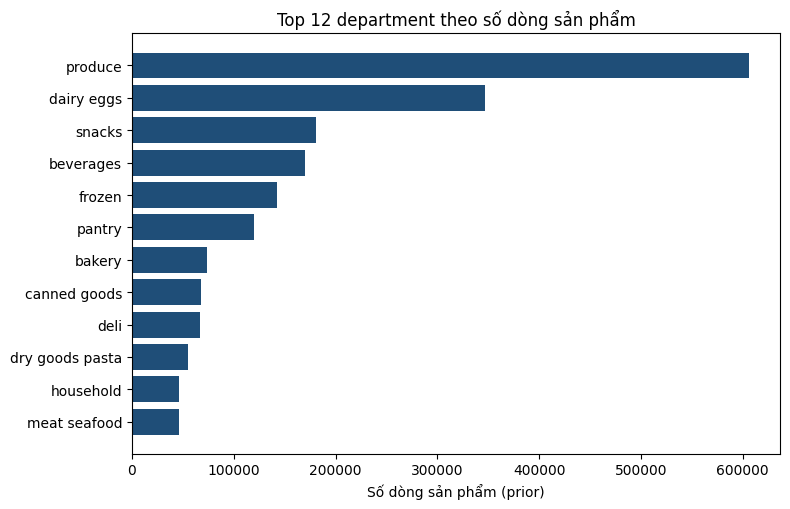

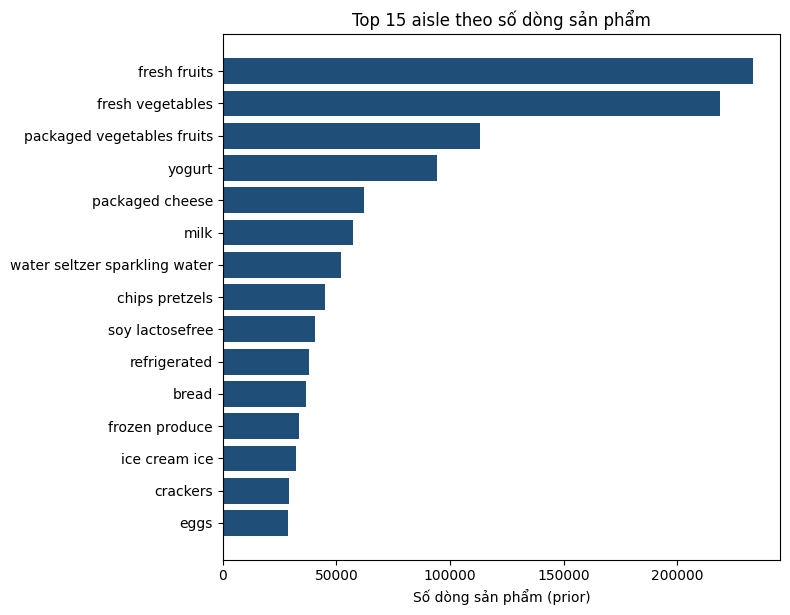

True

In [7]:
rollup_dept = q("""SELECT p.department, COUNT(*) AS luot, ROUND(100 * AVG(f.reordered), 2) AS reordered_pct,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS ty_trong_pct
FROM fact_order_product f JOIN dim_product p USING (product_id)
WHERE f.dataset_type = 'prior' GROUP BY 1 ORDER BY luot DESC""")
display(rollup_dept.head(8))
rollup_dept.to_csv(OUT3 / "rollup_department.csv", index=False, encoding="utf-8-sig")
drill_aisle = q("""SELECT p.department, p.aisle, COUNT(*) AS luot, ROUND(100 * AVG(f.reordered), 2) AS reordered_pct
FROM fact_order_product f JOIN dim_product p USING (product_id)
WHERE f.dataset_type = 'prior' GROUP BY 1, 2 ORDER BY luot DESC""")
display(drill_aisle.head(15))
drill_aisle.to_csv(OUT3 / "drilldown_aisle.csv", index=False, encoding="utf-8-sig")

for data, cot, n, ten, tep in [(rollup_dept, "department", 12, "Top 12 department theo số dòng sản phẩm", "h4_11_top_department.png"),
                               (drill_aisle, "aisle", 15, "Top 15 aisle theo số dòng sản phẩm", "h4_12_top_aisle.png")]:
    d = data.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.35 * n + 1))
    ax.barh(d[cot], d["luot"], color="#1F4E78")
    ax.set_xlabel("Số dòng sản phẩm (prior)"); ax.set_title(ten)
    fig.tight_layout(); fig.savefig(FIG3 / tep, dpi=150); plt.show(); plt.close(fig)

r = rollup_dept.set_index("department")
doi_chieu("produce: số lượt", int(r.loc["produce", "luot"]), 606397)
doi_chieu("produce: tỷ trọng (%)", float(r.loc["produce", "ty_trong_pct"]), 29.35, tol=0.005)
doi_chieu("dairy eggs: số lượt", int(r.loc["dairy eggs", "luot"]), 346404)
doi_chieu("produce + dairy eggs (%)", round(float(r.loc[["produce", "dairy eggs"], "ty_trong_pct"].sum()), 2), 46.12, tol=0.005)
doi_chieu("pantry: reordered (%)", float(r.loc["pantry", "reordered_pct"]), 34.64, tol=0.005)
a = drill_aisle.set_index("aisle")
doi_chieu("fresh fruits: số lượt", int(a.loc["fresh fruits", "luot"]), 233627)
doi_chieu("yogurt: số lượt", int(a.loc["yogurt", "luot"]), 94462)


## 6. Slice và Dice (Bảng 4.17, Bảng 4.18)

In [8]:
slice_produce = drill_aisle[drill_aisle["department"] == "produce"].reset_index(drop=True)
display(slice_produce)
slice_produce.to_csv(OUT3 / "slice_produce.csv", index=False, encoding="utf-8-sig")
dice = q("""SELECT p.department, o.order_dow, o.order_hour_of_day AS gio, COUNT(*) AS luot
FROM fact_order_product f JOIN dim_product p USING (product_id) JOIN dim_order o USING (order_id)
WHERE f.dataset_type = 'prior' AND p.department IN ('produce', 'dairy eggs', 'beverages')
  AND o.order_dow IN (0, 1) AND o.order_hour_of_day BETWEEN 9 AND 16
GROUP BY 1, 2, 3 ORDER BY luot DESC""")
display(dice.head(6))
dice.to_csv(OUT3 / "dice.csv", index=False, encoding="utf-8-sig")
s = slice_produce.set_index("aisle")
doi_chieu("fresh fruits: reordered (%)", float(s.loc["fresh fruits", "reordered_pct"]), 71.95, tol=0.005)
doi_chieu("fresh vegetables: reordered (%)", float(s.loc["fresh vegetables", "reordered_pct"]), 59.50, tol=0.005)
doi_chieu("Dice: số tổ hợp", len(dice), 48)
doi_chieu("Dice: produce, order_dow 0, 13 giờ", int(dice.iloc[0]["luot"]), 11554)


,department,aisle,luot,reordered_pct
0,produce,fresh fruits,233627,71.95
1,produce,fresh vegetables,218821,59.50
2,produce,packaged vegetables fruits,113041,64.11
3,produce,fresh herbs,23366,51.17
4,produce,packaged produce,17542,69.23


,department,order_dow,gio,luot
0,produce,0,13,11554
1,produce,0,15,11189
2,produce,0,14,11120
3,produce,0,12,11070
4,produce,0,10,10672
5,produce,1,10,10325


True

## 7. Bản đồ nhiệt theo order_dow và giờ, tỷ lệ reordered theo department (Hình 4.13, Hình 4.14)

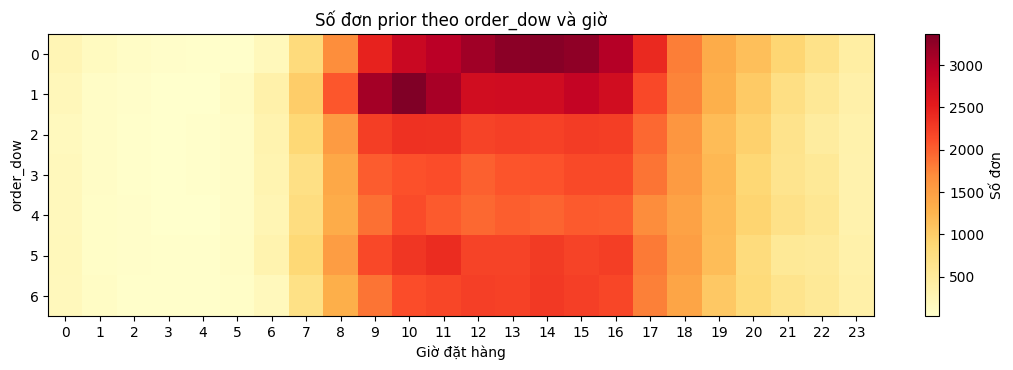

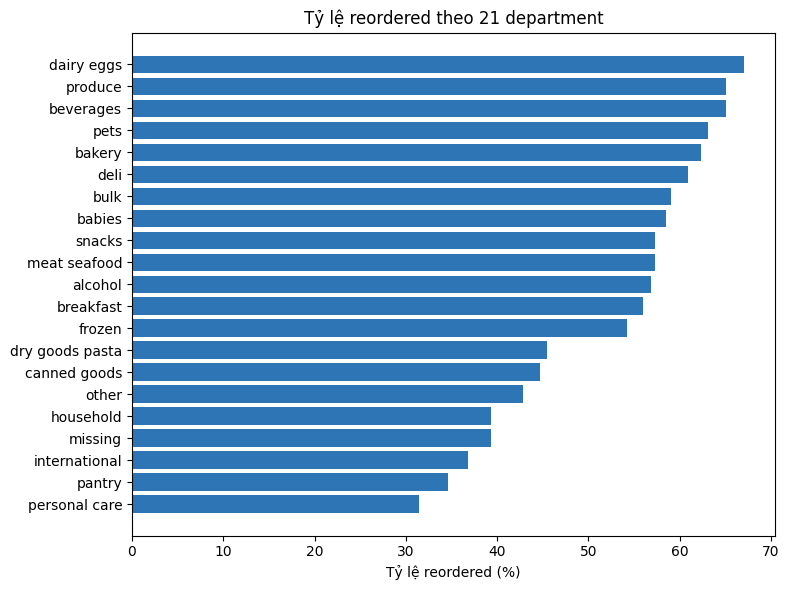

In [9]:
heat = q("""SELECT order_dow, order_hour_of_day AS gio, COUNT(DISTINCT order_id) AS so_don
FROM dim_order WHERE dataset_type = 'prior' GROUP BY 1, 2""").pivot(index="order_dow", columns="gio", values="so_don")
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(heat.index)), heat.index); ax.set_xticks(range(24), heat.columns)
ax.set_xlabel("Giờ đặt hàng"); ax.set_ylabel("order_dow"); ax.set_title("Số đơn prior theo order_dow và giờ")
fig.colorbar(im, ax=ax, label="Số đơn"); fig.tight_layout(); fig.savefig(FIG3 / "h4_13_heatmap.png", dpi=150); plt.show(); plt.close(fig)

d = rollup_dept.sort_values("reordered_pct")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(d["department"], d["reordered_pct"], color="#2E75B6")
ax.set_xlabel("Tỷ lệ reordered (%)"); ax.set_title("Tỷ lệ reordered theo 21 department")
fig.tight_layout(); fig.savefig(FIG3 / "h4_14_reordered_department.png", dpi=150); plt.show(); plt.close(fig)


## 8. ROLLUP và Data Cube (Bảng 4.19)

In [10]:
rollup = q("""SELECT p.department, o.order_dow, COUNT(*) AS luot
FROM fact_order_product f JOIN dim_product p USING (product_id) JOIN dim_order o USING (order_id)
WHERE f.dataset_type = 'prior' GROUP BY ROLLUP (p.department, o.order_dow)""")
cube = q("""SELECT p.department, o.order_dow, o.order_hour_of_day AS gio, COUNT(*) AS luot,
       COUNT(DISTINCT f.order_id) AS so_don
FROM fact_order_product f JOIN dim_product p USING (product_id) JOIN dim_order o USING (order_id)
WHERE f.dataset_type = 'prior' GROUP BY CUBE (p.department, o.order_dow, o.order_hour_of_day)""")
rollup.to_csv(OUT3 / "rollup_department_dow.csv", index=False, encoding="utf-8-sig")
cube.to_csv(OUT3 / "cube_department_dow_gio.csv", index=False, encoding="utf-8-sig")
tong_rollup = rollup[rollup["department"].isna() & rollup["order_dow"].isna()]
tong_cube = cube[cube["department"].isna() & cube["order_dow"].isna() & cube["gio"].isna()]
theo_gio = cube[cube["department"].isna() & cube["order_dow"].isna() & cube["gio"].notna()].sort_values("luot", ascending=False)
display(theo_gio.head(6)[["gio", "luot"]])
doi_chieu("ROLLUP: số dòng", len(rollup), 169)
doi_chieu("ROLLUP: dòng tổng cộng", int(tong_rollup["luot"].iloc[0]), 2066000)
doi_chieu("CUBE: số dòng", len(cube), 4331)
doi_chieu("CUBE: tổng lượt", int(tong_cube["luot"].iloc[0]), 2066000)
doi_chieu("CUBE: tổng số đơn", int(tong_cube["so_don"].iloc[0]), 206657)
doi_chieu("CUBE: 11 giờ", int(theo_gio.set_index("gio").loc[11, "luot"]), 174203)


,gio,luot
4227,11,174203
4225,10,173935
4325,13,171733
4228,15,168644
4224,14,167701
4320,12,165939


True

## 9. Tổng hợp đối chiếu với báo cáo

In [11]:
bang = pd.DataFrame(CHECKS)
display(bang)
so_lech = int((~bang["khop"]).sum())
print(f"Đối chiếu với báo cáo: {len(bang) - so_lech}/{len(bang)} chỉ tiêu khớp")
assert so_lech == 0, "Có chỉ tiêu lệch với báo cáo, xem bảng trên"
con.close()
print("Tệp DuckDB cho bước 4:", DB_PATH)


,chi_tieu,thuc_te,bao_cao,khop
0,Tổng số vi phạm của 10 phép kiểm tra,0,0,True
1,Bảng 4.15: dim_user,13121,13121,True
2,Bảng 4.15: dim_order,219778,219778,True
3,Bảng 4.15: dim_product,49688,49688,True
4,Bảng 4.15: fact_order_product,2205019,2205019,True
5,Bảng 4.15: transactions_aisle,206657,206657,True
6,Bảng 4.15: transactions_department,206657,206657,True
7,Số dòng prior,2066000,2066000,True
8,Tỷ lệ reordered prior (%),58.94,58.94,True
9,produce: số lượt,606397,606397,True


Đối chiếu với báo cáo: 26/26 chỉ tiêu khớp
Tệp DuckDB cho bước 4: /content/drive/MyDrive/Nhom04_ADM/repo/data/processed/step3_transactions_for_association_mining.duckdb
